# Feature selection: does each of the 38 inputs earn its place? (report appendix)

The model reads **38 inputs**: the 28 weekly store features, the 8 adopted 4-week features, `weeks_since_open` and
the application score. The list is **frozen** (decision 28 Oct 2026) for calibration and the test months, so this
notebook does not change it. It answers the report's question "is every input useful, or are some copies or dead
weight?", and records how much a smaller list would cost.

The model is the one the team uses from tuning step 2 on: the same 38 inputs with the **tuned LightGBM settings**
(`outputs/modelling/models/v1_full/lgbm_tuning_step2/tuned_params.json`, notebook 08). Two measures are scored on the
same shuffles:

- **weekly recall**, the team's tuning measure (share of each week's mules in that week's top 1% of open accounts,
  mean over weeks 0–26; decision 26 Oct 2026);
- **catch_rules**, the proposed measure (28 Oct 2026): flags are permanent and limited to the rules' own alert count in
  each week since opening (~6 a week per month); the share of mule accounts already flagged, mean over weeks 0–26.
  It is the budget the final comparison with the rules uses.

| § | What | Question |
|---|---|---|
| 0 | Setup | |
| 1 | The table | same rows, folds and application score as the feature lab |
| 2 | Inventory | how much signal does each feature carry on its own? |
| 3 | Near-duplicates | which features are almost copies of each other? |
| 4 | What the model relies on | how much do the two measures fall when a feature (or its copies) is shuffled? |
| 5 | Summary | a label per feature and per family |
| 6 | Refit check and report | what refitting without the weak inputs would cost |

**Rules kept.** Training months 0–4 only, the baseline's three folds (train 0–1 → validate 2, 0–2 → 3, 0–3 → 4);
month 5 and test months 6–7 are never read. Labels only through `amldata`.

## 0. Setup

In [1]:
from __future__ import annotations
import os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# find the repo root (the folder holding src/amldata) so Run All works from notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import lightgbm as lgb
from sklearn.metrics import roc_auc_score
import amldata
from features import candidates
from features.weekly import FEATURES as WEEKLY
from models import feature_lab as lab
from models import feature_selection as fs
from models.lgbm_baseline import FOLDS, KEY, load_table, profiles

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)     # data/v1_full by default; data/v1 for a quick run
RUN = os.path.basename(os.path.normpath(OUT))
REPORT = Path(os.environ.get("EDA_REPORT", "outputs/modelling/feature_selection" + ("" if RUN == "v1_full" else f"/{RUN}")))
REPORT.mkdir(parents=True, exist_ok=True)
MONTHS = (0, 1, 2, 3, 4)
WEEKS = (0, 26)          # main horizon, weeks since opening
SEED = 42
COLS = fs.ALL_INPUTS     # the tuned model's 38 inputs, in the feature lab's order
CLUSTER_AT = 0.8         # assumption: |Spearman| >= 0.8 for every pair = near-duplicates (0.7 / 0.9 shown too)
REPEATS = 3              # shuffles per feature per fold
MEASURES = ["weekly_recall", "catch_rules"]
# assumption: a shuffle that costs at least this much, in all 3 folds, makes an input 'needed'. catch_rules gets twice
# weekly recall's line because its measured refit noise is about twice as large (0.012 vs 0.006, trial noise-placebo5)
NEEDED = {"weekly_recall": 0.005, "catch_rules": 0.010}
PARAMS_FILE = os.environ.get("FEATSEL_PARAMS", "outputs/modelling/models/v1_full/lgbm_tuning_step2/tuned_params.json")
PARAMS = lab.read_params(PARAMS_FILE if PARAMS_FILE and os.path.exists(PARAMS_FILE) else None)
SETTINGS = lab.lgbm_settings(SEED, PARAMS)
INK, MUTED, GRID, BLUE = "#0b0b0b", "#898781", "#e1e0d9", "#2a78d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.edgecolor": "#c3c2b7", "font.size": 10, "text.color": INK})
show = (lambda x: display(x)) if "ipykernel" in sys.modules else print
T0 = time.time()
print(f"data {OUT} -> report {REPORT} | lightgbm {lgb.__version__} | settings: "
      f"{PARAMS_FILE if PARAMS else 'LightGBM defaults'}")
print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in SETTINGS.items()})

data data/v1_full -> report outputs\modelling\feature_selection | lightgbm 4.7.0 | settings: outputs/modelling/models/v1_full/lgbm_tuning_step2/tuned_params.json
{'class_weight': 'balanced', 'random_state': 42, 'n_jobs': -1, 'verbose': -1, 'deterministic': True, 'force_row_wise': True, 'learning_rate': 0.03274, 'n_estimators': 500, 'num_leaves': 15, 'min_child_samples': 2000, 'colsample_bytree': 0.90475, 'subsample': 0.91886, 'reg_alpha': 4e-05, 'reg_lambda': 0.00046, 'subsample_freq': 1}


## 1. The table

Exactly the feature lab's table: one row per account per open week 0–26 (weeks after the bank closed an account are
dropped), the 28 store features, the 8 adopted 4-week features, `weeks_since_open`, and the label `mule_by_day`.
The **application score** is a logistic regression on the 56 prepared application columns, built per fold as in
notebook 06 (out of fold for training accounts). The raw application columns are not model inputs here, so they are
left out of the table to save memory.

In [2]:
df, _ = load_table(OUT, MONTHS, WEEKS, adopted=True)
df = df[KEY + ["open_month", "mule_by_day"] + WEEKLY + candidates.ADOPTED]
df = df.sort_values(KEY, kind="stable").reset_index(drop=True)
scores = {f: s["app_score"] for f, s in lab.app_scores(OUT, SEED).items()}   # per fold: account -> app score
prof = profiles(OUT, MONTHS)                     # hidden type, for breakdowns only
ctx = lab.rules_context(OUT)                     # mule weeks and the rules' weekly alert counts, for catch_rules
print(f"{len(df):,} account-weeks, {int(df['mule_by_day'].sum()):,} mule weeks ({df['mule_by_day'].mean():.3%}); "
      f"{df['account_id'].nunique():,} accounts; {len(COLS)} inputs in {len(fs.FAMILIES)} families "
      f"({time.time() - T0:.0f}s)")
show(pd.DataFrame({"features": [", ".join(c) for c in fs.FAMILIES.values()],
                   "n": [len(c) for c in fs.FAMILIES.values()]}, index=list(fs.FAMILIES)))

4,449,169 account-weeks, 8,327 mule weeks (0.187%); 164,819 accounts; 38 inputs in 10 families (2223s)


,features,n
volume_wk,"n_rows_wk, n_in_wk, n_out_wk, money_in_wk, mon...",8
volume_cum,"n_rows_cum, money_in_cum, money_out_cum",3
counterparties,"n_payers_wk, n_payees_wk, new_payer_share_wk, ...",5
flow,"passthrough_wk, out_1h_share_wk, out_24h_share...",4
self_vs_past,"self_vs_past_money_in, self_vs_past_payers, se...",3
peer,peer_ratio_money_in,1
mix,"internal_out_share_cum, cash_in_share_cum, abr...",4
window_4wk,"n_rows_4wk, n_in_4wk, money_in_4wk, money_out_...",8
clock,weeks_since_open,1
application,app_score,1


## 2. Inventory: signal on its own

Two views per feature, both on months 0–4:

- **Screen (started vs normal)**: AUC at weeks 8, 12 and 26 between launderers whose laundering has begun and normal
  accounts, with a 95% interval over launderers (the feature lab's screen). The table keeps the week with the largest
  separation. 0.5 = no signal; below 0.5 means *lower* values point to laundering.
- **All weeks (mule_by_day)**: AUC against the model's own label over every account-week 0–26. Fake accounts count as
  mules from opening, so this view rewards features that see fakes early.

Single-feature signal is only a first look: a weak feature can help in combination, and a strong one can be a copy of
another. Sections 3 and 4 test those cases. For the application score, the last fold's scores are used (months 0–3 out
of fold, month 4 from a model fitted on months 0–3).

In [3]:
df["app_score"] = df["account_id"].map(scores[len(FOLDS)])
scr = lab.screen(OUT, df, COLS)
scr["sep"] = (scr["auc"] - 0.5).abs()
best = scr.loc[scr.groupby("feature")["sep"].idxmax()].set_index("feature")
y = df["mule_by_day"].to_numpy()


def nan_lowest(x):
    # missing values rank lowest, as in the EDA's AUC helper (no money in -> no share)
    x = np.asarray(x, dtype=float)
    return np.where(np.isnan(x), np.nanmin(x) - 1, x)


inv = pd.DataFrame({
    "family": [fs.FAMILY_OF[c] for c in COLS],
    "screen_auc": best.loc[COLS, "auc"].to_numpy(),
    "screen_week": best.loc[COLS, "week"].to_numpy(),
    "screen_ci": [f"{best.loc[c, 'lo']:.2f}-{best.loc[c, 'hi']:.2f}" for c in COLS],
    "screen_signal": [(best.loc[c, "lo"] > 0.5) or (best.loc[c, "hi"] < 0.5) for c in COLS],
    "all_weeks_auc": [roc_auc_score(y, nan_lowest(df[c])) for c in COLS],
    "missing": [df[c].isna().mean() for c in COLS],
}, index=pd.Index(COLS, name="feature"))
print(f"{int(inv['screen_signal'].sum())} of {len(COLS)} features separate started launderers from normal accounts "
      f"(interval excludes 0.5) at one of weeks 8 / 12 / 26")
show(inv.sort_values("screen_auc", key=lambda s: (s - 0.5).abs(), ascending=False).round(3))

37 of 38 features separate started launderers from normal accounts (interval excludes 0.5) at one of weeks 8 / 12 / 26


,family,screen_auc,screen_week,screen_ci,screen_signal,all_weeks_auc,missing
feature,,,,,,,
out_1h_share_4wk,window_4wk,0.934,12,0.91-0.96,True,0.613,0.044
out_24h_share_4wk,window_4wk,0.908,12,0.88-0.93,True,0.607,0.044
n_in_4wk,window_4wk,0.886,12,0.86-0.91,True,0.591,0.000
n_rows_4wk,window_4wk,0.880,12,0.85-0.91,True,0.585,0.000
n_rows_cum,volume_cum,0.864,8,0.79-0.92,True,0.516,0.000
money_out_4wk,window_4wk,0.855,12,0.82-0.89,True,0.629,0.000
n_payers_cum,counterparties,0.834,8,0.74-0.91,True,0.561,0.000
n_payers_4wk,window_4wk,0.830,12,0.80-0.86,True,0.576,0.000
money_in_4wk,window_4wk,0.830,12,0.80-0.86,True,0.620,0.000


## 3. Near-duplicates

Spearman correlation (rank-based, so it is not thrown by the long tails of money amounts) between every pair of
inputs, on a random 200,000 account-weeks. Features are then grouped so that **every pair inside a group has
|ρ| ≥ 0.8** (complete-linkage clustering; 0.8 is an assumption, the counts at 0.7 and 0.9 are printed too).
Inside such a group the model can use any member almost as well as the others, so the group usually needs only one
or two of them. Which one to keep is decided by section 4 and by which is easiest to explain.

|rho| >= 0.7: 7 groups of near-duplicates holding 23 features; 15 features stand alone


|rho| >= 0.8: 7 groups of near-duplicates holding 20 features; 18 features stand alone


|rho| >= 0.9: 6 groups of near-duplicates holding 14 features; 24 features stand alone


,members,n,min_abs_rho
C1,"n_out_wk, n_payees_wk",2,0.935
C2,"n_rows_wk, self_vs_past_rows",2,0.870
C12,"money_out_wk, max_out_wk",2,0.830
C17,"n_in_wk, money_in_wk, max_in_wk, n_payers_wk, ...",7,0.813
C18,"n_in_4wk, n_payers_4wk",2,0.962
C22,"money_in_cum, money_out_cum",2,0.965
C23,"n_rows_cum, n_payees_cum, weeks_since_open",3,0.929


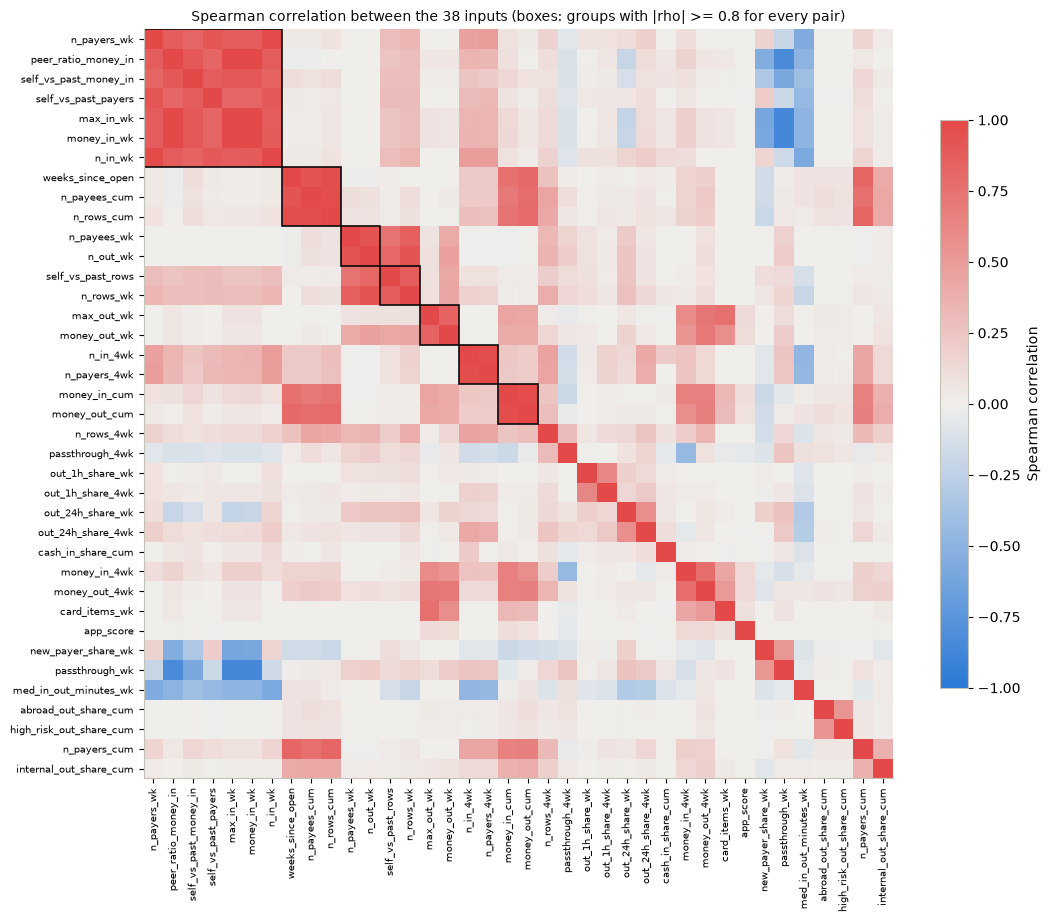

In [4]:
rho, cl = fs.spearman_clusters(df, COLS, threshold=CLUSTER_AT, seed=SEED)
for t in (0.7, 0.8, 0.9):
    c = fs.spearman_clusters(df, COLS, threshold=t, seed=SEED)[1]
    sizes = c.value_counts()
    print(f"|rho| >= {t}: {int((sizes > 1).sum())} groups of near-duplicates holding {int(sizes[sizes > 1].sum())} "
          f"features; {int((sizes == 1).sum())} features stand alone")

groups_multi = {}
for k, members in cl.groupby(cl).groups.items():
    members = list(members)
    if len(members) > 1:
        groups_multi[f"C{k}"] = members
groups_tab = pd.DataFrame({
    "members": [", ".join(m) for m in groups_multi.values()],
    "n": [len(m) for m in groups_multi.values()],
    "min_abs_rho": [rho.loc[m, m].abs().to_numpy()[np.triu_indices(len(m), 1)].min() for m in groups_multi.values()],
}, index=list(groups_multi))
show(groups_tab.round(3))

# heatmap, features ordered by group (near-duplicates sit together), then family
order = sorted(COLS, key=lambda c: (-(cl == cl[c]).sum(), cl[c], fs.FAMILY_OF[c], c))
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(rho.loc[order, order].to_numpy(), cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order)), order, fontsize=7)
ax.grid(False)
pos = {c: i for i, c in enumerate(order)}
for m in groups_multi.values():                    # outline each near-duplicate group
    idx = sorted(pos[c] for c in m)
    ax.add_patch(plt.Rectangle((idx[0] - 0.5, idx[0] - 0.5), len(idx), len(idx), fill=False, ec=INK, lw=1.2))
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title(f"Spearman correlation between the 38 inputs (boxes: groups with |rho| >= {CLUSTER_AT} for every pair)",
             fontsize=10)
fig.tight_layout()
fig.savefig(REPORT / "01_spearman_heatmap.png", dpi=130)
plt.show() if "ipykernel" in sys.modules else plt.close(fig)

## 4. What the model relies on

For each fold the model is refitted as in the feature lab, with the tuned settings printed in §0 (balanced classes,
seed 42, deterministic). Its validation month is then scored again with one input **shuffled** (its values moved to
random other rows), three times each. The fall in each measure is that input's **permutation importance**: how much
the model loses when the input carries no information. Both measures are computed on the same shuffled scores.

Shuffling one member of a near-duplicate group understates its value, because the model can lean on the other members.
So whole groups from section 3, and whole families, are also shuffled together.

Two cheaper views are kept beside it for comparison: **gain** (how much each input improved the trees' splits while
training; known to favour continuous inputs) and **mean |SHAP|** (LightGBM's own per-row contributions, on all mule
rows plus 50,000 normal rows of the validation month; it also shows the direction of each effect).

This section takes the longest (on the full dataset several hours with the tuned settings). Each finished fold is
saved under `<data>/features/feature_selection_cache/` (git-ignored, beside the data), so a rerun with the same
settings picks up where it stopped; delete that folder to start again.

In [5]:
def measures_for(valid_m):
    mules = ctx["mules"][ctx["mules"]["open_month"] == valid_m]
    budget = ctx["budget"][valid_m]

    def measure(valid, s):
        v = lab.weekly_top1(valid, s)
        return {"weekly_recall": lab.weekly_recall(v),
                "catch_rules": lab.catch_mean(lab.first_flag_weeks(v, budget), mules)}
    return measure


GROUPS = ({c: [c] for c in COLS} | groups_multi
          | {f"family {f}": c for f, c in fs.FAMILIES.items() if len(c) > 1})
import hashlib, json
CACHE = Path(OUT) / "features" / "feature_selection_cache"
CACHE.mkdir(parents=True, exist_ok=True)
STAMP = hashlib.sha256(json.dumps({"settings": SETTINGS, "groups": GROUPS, "repeats": REPEATS, "seed": SEED,
                                   "cols": COLS}, sort_keys=True, default=str).encode()).hexdigest()[:12]

perm, gains, shaps, base_rows = [], [], [], []
for f, (train_m, valid_m) in enumerate(FOLDS, start=1):
    t = time.time()
    saved = {k: CACHE / f"{STAMP}_fold{f}_{k}.parquet" for k in ("perm", "gain", "shap", "base")}
    if all(p.exists() for p in saved.values()):                  # finished in an earlier run with the same settings
        p, g_, s_, b_ = (pd.read_parquet(saved[k]) for k in ("perm", "gain", "shap", "base"))
        perm.append(p); gains.append(g_); shaps.append(s_); base_rows.append(b_.iloc[0].to_dict())
        print(f"fold {f}: loaded from {CACHE} (settings {STAMP})")
        continue
    df["app_score"] = df["account_id"].map(scores[f])
    train, valid = df[df["open_month"].isin(train_m)], df[df["open_month"] == valid_m]
    model = lgb.LGBMClassifier(**SETTINGS)
    model.fit(train[COLS], train["mule_by_day"])
    g = model.booster_.feature_importance("gain")
    gains.append(pd.DataFrame({"feature": COLS, "gain_share": g / g.sum(), "fold": f}))
    p = fs.permutation_drop(model, valid, COLS, GROUPS, measures_for(valid_m), repeats=REPEATS, seed=SEED + f)
    perm.append(p.assign(fold=f))
    b = p.groupby("measure")["base"].first()
    rules = lab.catch_mean(ctx["rules_first"], ctx["mules"][ctx["mules"]["open_month"] == valid_m])
    base_rows.append({"fold": f, **b.to_dict(), "rules_catch": rules})
    rows = pd.concat([valid[valid["mule_by_day"] == 1],
                      valid[valid["mule_by_day"] == 0].sample(min(50_000, int((valid["mule_by_day"] == 0).sum())),
                                                              random_state=SEED)])
    shaps.append(fs.mean_abs_contrib(model, rows[COLS]).assign(fold=f))
    for k, x in {"perm": perm[-1], "gain": gains[-1], "shap": shaps[-1], "base": pd.DataFrame([base_rows[-1]])}.items():
        x.to_parquet(saved[k], index=False)
    print(f"fold {f} (train {train_m} -> valid {valid_m}): weekly recall {b['weekly_recall']:.3f}, catch_rules "
          f"{b['catch_rules']:.3f} (rules' own alerts {rules:.3f}); {len(GROUPS)} groups x {REPEATS} shuffles "
          f"({time.time() - t:.0f}s)")
perm, gains, shaps = (pd.concat(x, ignore_index=True) for x in (perm, gains, shaps))
baseline = pd.DataFrame(base_rows).set_index("fold")
show(baseline.round(3))

fold 1 (train (0, 1) -> valid 2): weekly recall 0.428, catch_rules 0.464 (rules' own alerts 0.146); 52 groups x 3 shuffles (21333s)


fold 2 (train (0, 1, 2) -> valid 3): weekly recall 0.397, catch_rules 0.455 (rules' own alerts 0.132); 52 groups x 3 shuffles (3587s)


fold 3 (train (0, 1, 2, 3) -> valid 4): weekly recall 0.470, catch_rules 0.436 (rules' own alerts 0.143); 52 groups x 3 shuffles (2655s)


,catch_rules,weekly_recall,rules_catch
fold,,,
1,0.464,0.428,0.146
2,0.455,0.397,0.132
3,0.436,0.470,0.143


## 5. Summary

Per input and per measure: the mean fall over the three folds (each fold's three shuffles averaged first), how many
folds fell, and the same for its near-duplicate group. Labels (thresholds are assumptions, stated in §0):

| label | meaning |
|---|---|
| **needed** | shuffling it alone costs at least the 'needed' line in all 3 folds, on either measure |
| **covered by a near-copy** | alone it costs little, but its group of near-duplicates is needed: keep one or two members |
| **mixed** | reaches the line on average on either measure, but not in every fold: unclear |
| **weak** | below the line on average on both measures, and its group is not needed |

These labels are evidence for the appendix, not decisions: the input list is frozen.

,family,screen_auc,screen_signal,all_weeks_auc,near_copy_group,drop_weekly_recall,folds_down_weekly_recall,group_drop_weekly_recall,drop_catch_rules,folds_down_catch_rules,group_drop_catch_rules,gain_share,mean_abs_shap,direction,needed_on,label
feature,,,,,,,,,,,,,,,,
app_score,application,0.7962,True,0.8052,,0.1572,3,NaN,0.0316,3,NaN,0.5071,1.0920,0.8701,"weekly_recall, catch_rules",needed
out_1h_share_4wk,window_4wk,0.9338,True,0.6133,,0.0845,3,NaN,0.2599,3,NaN,0.1182,0.0772,0.1610,"weekly_recall, catch_rules",needed
n_payers_cum,counterparties,0.8335,True,0.5605,,0.0566,3,NaN,-0.0028,1,NaN,0.0666,0.1978,-0.1982,weekly_recall,needed
weeks_since_open,clock,0.5000,False,0.4799,C23,0.0466,3,0.0579,0.0029,3,0.0031,0.0222,0.6217,-0.8899,weekly_recall,needed
internal_out_share_cum,mix,0.6234,True,0.5337,,0.0434,3,NaN,0.0025,1,NaN,0.0368,0.1527,-0.2505,weekly_recall,needed
money_out_cum,volume_cum,0.7452,True,0.5661,C22,0.0375,3,0.0868,-0.0043,1,0.0080,0.0239,0.1823,0.7739,weekly_recall,needed
money_in_cum,volume_cum,0.7245,True,0.5697,C22,0.0269,3,0.0868,0.0019,3,0.0080,0.0211,0.1604,0.8943,weekly_recall,needed
n_rows_cum,volume_cum,0.8642,True,0.5161,C23,0.0221,3,0.0579,0.0024,3,0.0031,0.0186,0.1212,-0.0514,weekly_recall,needed
money_in_4wk,window_4wk,0.8298,True,0.6205,,0.0211,3,NaN,0.0553,3,NaN,0.0567,0.1671,-0.1531,"weekly_recall, catch_rules",needed


label
needed                    15
weak                      14
covered by a near-copy     9


,n,drop_weekly_recall,folds_down_weekly_recall,drop_catch_rules,folds_down_catch_rules,needed_members,family_needed
family,,,,,,,
application,1,0.1572,3,0.0316,3,1,True
window_4wk,8,0.1484,3,0.3414,3,5,True
volume_cum,3,0.0915,3,0.0163,3,3,True
counterparties,5,0.0613,3,-0.0009,1,1,True
mix,4,0.0517,3,0.0016,1,3,True
clock,1,0.0466,3,0.0029,3,1,True
volume_wk,8,0.0077,3,0.0041,2,1,True
flow,4,0.0046,3,0.0063,2,0,False
self_vs_past,3,0.0042,3,0.0045,3,0,False


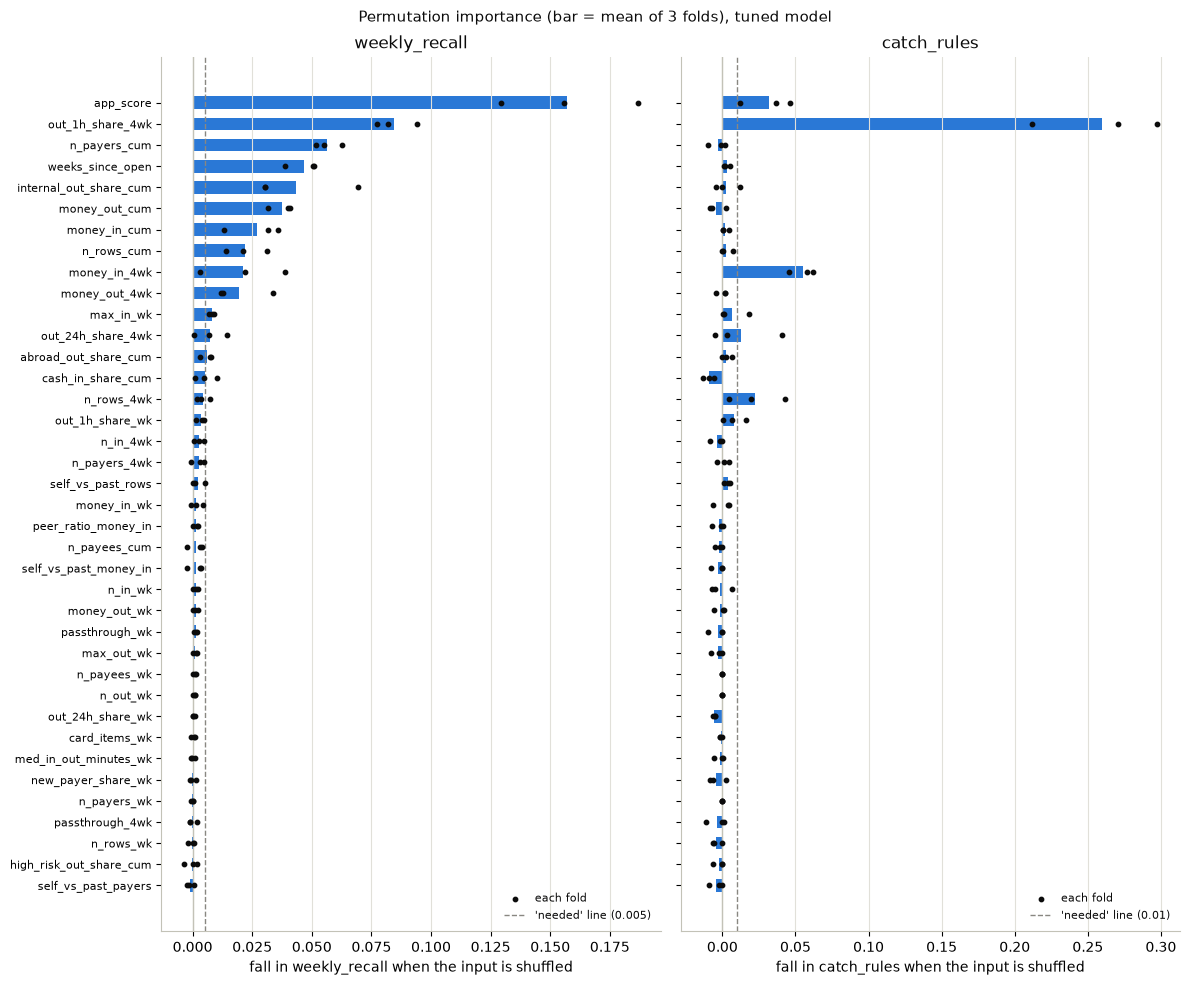

In [6]:
def stats(m):
    pf = perm[perm["measure"] == m].groupby(["group", "fold"])["drop"].mean().unstack("fold")
    return pf, pd.DataFrame({"drop": pf.mean(axis=1), "folds_down": (pf > 0).sum(axis=1)})


per_fold, stat = {}, {}
for m in MEASURES:
    per_fold[m], stat[m] = stats(m)


def needed(g, m):
    return bool(stat[m].loc[g, "folds_down"] == len(FOLDS) and stat[m].loc[g, "drop"] >= NEEDED[m])


group_of = {c: k for k, m in groups_multi.items() for c in m}
summary = inv[["family", "screen_auc", "screen_signal", "all_weeks_auc"]].copy()
summary["near_copy_group"] = [group_of.get(c, "") for c in COLS]
for m in MEASURES:
    summary[f"drop_{m}"] = stat[m].loc[COLS, "drop"].to_numpy()
    summary[f"folds_down_{m}"] = stat[m].loc[COLS, "folds_down"].astype(int).to_numpy()
    summary[f"group_drop_{m}"] = [stat[m].loc[group_of[c], "drop"] if c in group_of else np.nan for c in COLS]
summary["gain_share"] = gains.groupby("feature")["gain_share"].mean().loc[COLS].to_numpy()
summary["mean_abs_shap"] = shaps.groupby("feature")["mean_abs_shap"].mean().loc[COLS].to_numpy()
summary["direction"] = shaps.groupby("feature")["direction"].mean().loc[COLS].to_numpy()


def label(c):
    if any(needed(c, m) for m in MEASURES):
        return "needed"
    if c in group_of and any(needed(group_of[c], m) for m in MEASURES):
        return "covered by a near-copy"
    if any(stat[m].loc[c, "drop"] >= NEEDED[m] for m in MEASURES):
        return "mixed"
    return "weak"


summary["needed_on"] = [", ".join(m for m in MEASURES if needed(c, m)) for c in COLS]
summary["label"] = [label(c) for c in COLS]
summary = summary.sort_values("drop_weekly_recall", ascending=False)
show(summary.round(4))
print(summary["label"].value_counts().to_string())


def fam_key(f, c):
    return f"family {f}" if len(c) > 1 else c[0]


fam = pd.DataFrame({"n": [len(c) for c in fs.FAMILIES.values()]}, index=pd.Index(list(fs.FAMILIES), name="family"))
for m in MEASURES:
    fam[f"drop_{m}"] = [stat[m].loc[fam_key(f, c), "drop"] for f, c in fs.FAMILIES.items()]
    fam[f"folds_down_{m}"] = [int(stat[m].loc[fam_key(f, c), "folds_down"]) for f, c in fs.FAMILIES.items()]
fam["needed_members"] = [int((summary.loc[c, "label"] == "needed").sum()) for c in fs.FAMILIES.values()]
fam["family_needed"] = [any(needed(fam_key(f, c), m) for m in MEASURES) for f, c in fs.FAMILIES.items()]
show(fam.sort_values("drop_weekly_recall", ascending=False).round(4))

# figure: permutation importance per input on each measure, bar = mean of 3 folds, dots = each fold
fig, axes = plt.subplots(1, 2, figsize=(12, 10), sharey=True)
idx = summary.index[::-1]
for ax, m in zip(axes, MEASURES):
    pf = per_fold[m].loc[idx]
    ax.barh(range(len(pf)), pf.mean(axis=1), color=BLUE, height=0.6)
    for j in pf.columns:
        ax.scatter(pf[j], range(len(pf)), color=INK, s=10, zorder=3, label="each fold" if j == pf.columns[0] else None)
    ax.axvline(0, color="#c3c2b7", lw=1)
    ax.axvline(NEEDED[m], color=MUTED, lw=1, ls="--", label=f"'needed' line ({NEEDED[m]})")
    ax.grid(axis="y", visible=False)
    ax.set(xlabel=f"fall in {m} when the input is shuffled", title=m)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_yticks(range(len(idx)), idx, fontsize=8)
fig.suptitle("Permutation importance (bar = mean of 3 folds), tuned model", fontsize=11)
fig.tight_layout()
fig.savefig(REPORT / "02_permutation_importance.png", dpi=130)
plt.show() if "ipykernel" in sys.modules else plt.close(fig)

## 6. Refit check and report

Shuffling one input at a time can miss inputs that only matter *together*, so the labels are checked by refitting
the model without them (`python -m models.feature_lab --drop ... --together`, same tuned settings). The lab reports
both measures per fold, real-customer mules caught and catching within two weeks of the start. Two refits, from
cautious to bold:

1. **without the weak inputs**;
2. **also without the spare near-copies**: in a group of near-duplicates with a needed member, the members labelled
   "covered"; in a group without one, every member except the one whose shuffle costs most.

"Mixed" inputs stay in both. Every refit lands in the feature lab's ledger, so the number of looks is on record.

In [7]:
weak = list(summary.index[summary["label"] == "weak"])
spare = []
for k, m in groups_multi.items():
    lab_m = summary.loc[m, "label"]
    covered = list(lab_m.index[lab_m == "covered by a near-copy"])
    if not (lab_m == "needed").any() and covered:     # keep the strongest member of a group with no needed member
        covered.remove(summary.loc[covered, "drop_weekly_recall"].idxmax())
    spare += covered
trials = {f"drop-weak-tuned-{RUN}": weak, f"drop-weak-and-copies-tuned-{RUN}": weak + spare}
params_arg = f" --params {PARAMS_FILE}" if PARAMS else ""
cmds = [f"python -m models.feature_lab --out {OUT} --drop {' '.join(cols)} --together{params_arg} --name {name}"
        for name, cols in trials.items() if cols]
baseline.to_csv(REPORT / "baseline.csv")
print(f"weak ({len(weak)}): {', '.join(weak) or 'none'}")
print(f"spare near-copies ({len(spare)}): {', '.join(spare) or 'none'}")
print(f"inputs left after trial 2: {len(COLS) - len(weak) - len(spare)} of {len(COLS)}")
print("\n".join(cmds) or "(nothing to drop)")

inv.to_csv(REPORT / "inventory.csv")
rho.to_csv(REPORT / "spearman.csv")
groups_tab.to_csv(REPORT / "near_copy_groups.csv")
perm.to_csv(REPORT / "permutation.csv", index=False)
summary.to_csv(REPORT / "summary.csv")
fam.to_csv(REPORT / "families.csv")
lines = [
    f"# Feature selection ({RUN}): does each of the 38 frozen inputs earn its place?", "",
    "Report-appendix work. The input list is frozen (decision 28 Oct 2026); nothing here changes it.", "",
    f"Data `{OUT}`, training months 0-4, weeks 0-26, 3 folds, seed {SEED}, lightgbm {lgb.__version__}, LightGBM "
    f"settings {('`' + PARAMS_FILE + '`') if PARAMS else 'defaults'}. Executed copy: `12_feature_selection.ipynb`. "
    f"Thresholds (assumptions): near-duplicates |rho| >= {CLUSTER_AT}; 'needed' = the measure falls by at least "
    f"{NEEDED['weekly_recall']} (weekly recall) or {NEEDED['catch_rules']} (catch_rules) in all 3 folds when shuffled "
    f"({REPEATS} shuffles per fold).", "",
    "## Baseline per fold", "", baseline.round(3).to_markdown(), "",
    "`rules_catch` = catch_rules of the rules' own alerts on the same month.", "",
    "## Per input", "", summary.round(4).to_markdown(), "",
    "## Per family", "", fam.round(4).to_markdown(), "",
    f"## Near-duplicate groups (|rho| >= {CLUSTER_AT} for every pair)", "", groups_tab.round(3).to_markdown(), "",
    "![heatmap](01_spearman_heatmap.png)", "", "![permutation](02_permutation_importance.png)", "",
    "## Refit check: the model without them", "",
    f"- weak ({len(weak)}): {', '.join(weak) or 'none'}",
    f"- spare near-copies ({len(spare)}): {', '.join(spare) or 'none'}",
    f"- inputs left after trial 2: {len(COLS) - len(weak) - len(spare)} of {len(COLS)}", "",
    *[f"`{c}`" + "\n" for c in cmds],
    "Labels are evidence for the appendix, not decisions: the input list is frozen and changes only by team "
    "decision.", ""]
(REPORT / "report.md").write_text("\n".join(lines), encoding="utf-8")
print(f"-> {REPORT}  ({time.time() - T0:.0f}s total)")

weak (14): out_1h_share_wk, self_vs_past_rows, money_out_wk, passthrough_wk, max_out_wk, n_payees_wk, n_out_wk, out_24h_share_wk, card_items_wk, med_in_out_minutes_wk, new_payer_share_wk, passthrough_4wk, n_rows_wk, high_risk_out_share_cum
spare near-copies (8): n_in_wk, money_in_wk, n_payers_wk, self_vs_past_money_in, self_vs_past_payers, peer_ratio_money_in, n_payers_4wk, n_payees_cum
inputs left after trial 2: 16 of 38
python -m models.feature_lab --out data/v1_full --drop out_1h_share_wk self_vs_past_rows money_out_wk passthrough_wk max_out_wk n_payees_wk n_out_wk out_24h_share_wk card_items_wk med_in_out_minutes_wk new_payer_share_wk passthrough_4wk n_rows_wk high_risk_out_share_cum --together --params outputs/modelling/models/v1_full/lgbm_tuning_step2/tuned_params.json --name drop-weak-tuned-v1_full
python -m models.feature_lab --out data/v1_full --drop out_1h_share_wk self_vs_past_rows money_out_wk passthrough_wk max_out_wk n_payees_wk n_out_wk out_24h_share_wk card_items_wk med

-> outputs\modelling\feature_selection  (30172s total)
